# Solutions: Chapter 17, Interactive Charts with Plotly

Worked solutions to the exercises at the end of Chapter 17 of *Python for Data Science* by Vamsi Krishna Kandala. Try each exercise on your own first. Run the code yourself with the notebook [`ch17_solutions.ipynb`](ch17_solutions.ipynb) or the script `ch17_solutions.py`.

Numbers that depend on random data or library versions may differ slightly on your computer; the conclusions should not.


In [ ]:
# Setup: recreates the context these solutions build on (from the chapter).
from pathlib import Path

import numpy as np
import pandas as pd
import plotly.express as px

gap = pd.read_csv("data/gapminder.csv")
y2007 = gap[gap["year"] == 2007]
penguins = pd.read_csv("data/penguins.csv")
orders = pd.read_parquet("data/shop_orders.parquet")
orders = orders[orders["status"] != "cancelled"].assign(
    revenue=lambda d: d["quantity"] * d["unit_price"],
    month=lambda d: d["order_date"].dt.to_period("M").dt.start_time)

The solutions use the chapter's data: Gapminder with its 2007 rows as `y2007`, the penguins, and the coffee-shop orders with `revenue` and `month` columns. The pictures show the charts as printed; run the code to explore them interactively.

## Exercise 17.1

*Draw an interactive histogram of the penguins' body mass with `px.histogram`, colored by species, with `barmode="overlay"` and `opacity=0.6`.*

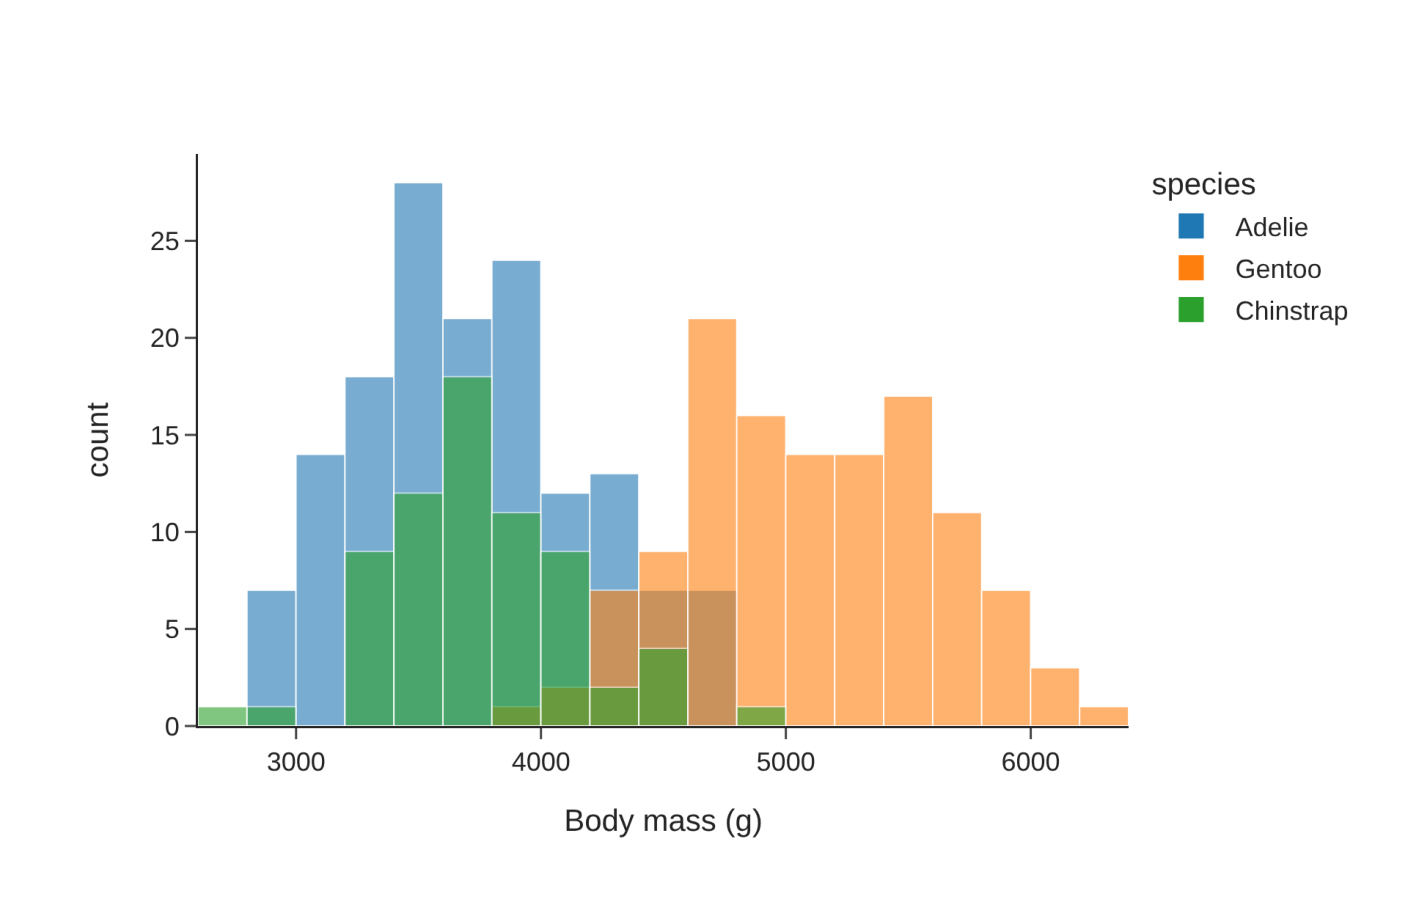

In [ ]:
fig = px.histogram(penguins, x="body_mass_g", color="species",
                   barmode="overlay", opacity=0.6, nbins=30,
                   template="simple_white",
                   labels={"body_mass_g": "Body mass (g)"})
fig.show()

*Overlaid histograms of body mass by species.*

`barmode="overlay"` draws the three histograms on top of each other instead of stacking them, and the opacity keeps the overlaps visible. In a browser, hovering over a bar shows its range and count, and clicking a species in the legend hides it, which separates Adelie from Chinstrap more easily than any static color choice.

## Exercise 17.2

*Draw a Plotly line chart of life expectancy for five countries, with hover boxes that show the population, formatted with thousands separators.*

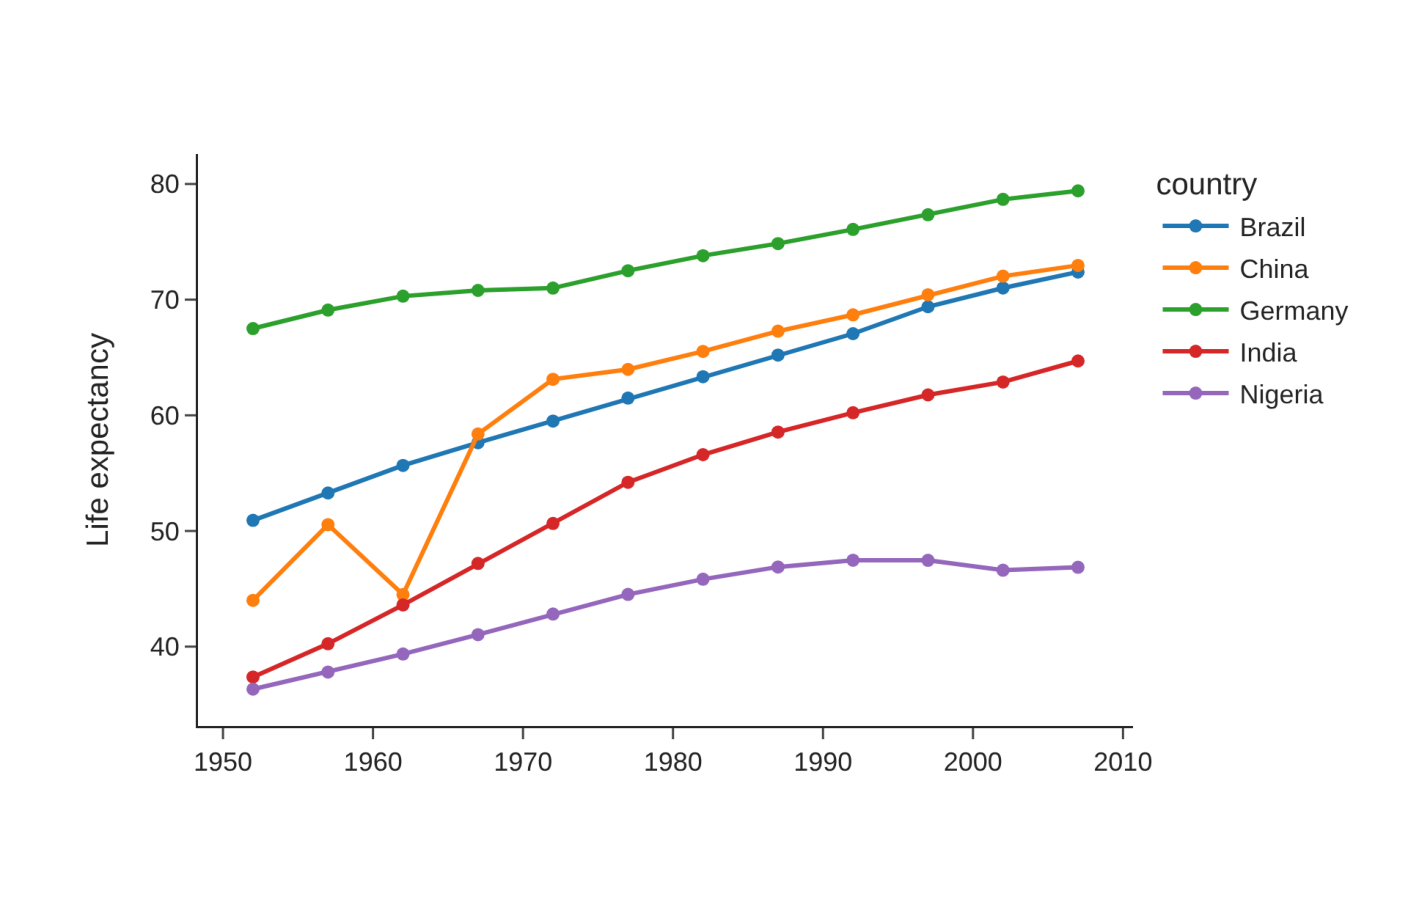

In [ ]:
five = gap[gap["country"].isin(["China", "India", "Brazil",
                                "Nigeria", "Germany"])]
fig = px.line(five, x="year", y="lifeExp", color="country",
              markers=True, hover_data={"pop": ":,.0f"},
              template="simple_white",
              labels={"lifeExp": "Life expectancy", "pop": "Population",
                      "year": ""})
fig.show()

*Life expectancy in five countries, 1952 to 2007.*

`hover_data` adds the population to every point's hover box. China's line shows the drop around 1962, the famine years, and the fastest rise of the five afterward. On paper, the population is invisible; on screen, it is one mouse movement away.

## Exercise 17.3

*Draw a box plot of delivery days by state with `px.box`, with every point shown. Which states have the slowest deliveries?*

{'MD': 4.22, 'NY': 4.37, 'PA': 4.37, 'NJ': 4.52, 'MA': 4.58, 'VA': 4.6, 'OH': 4.64}


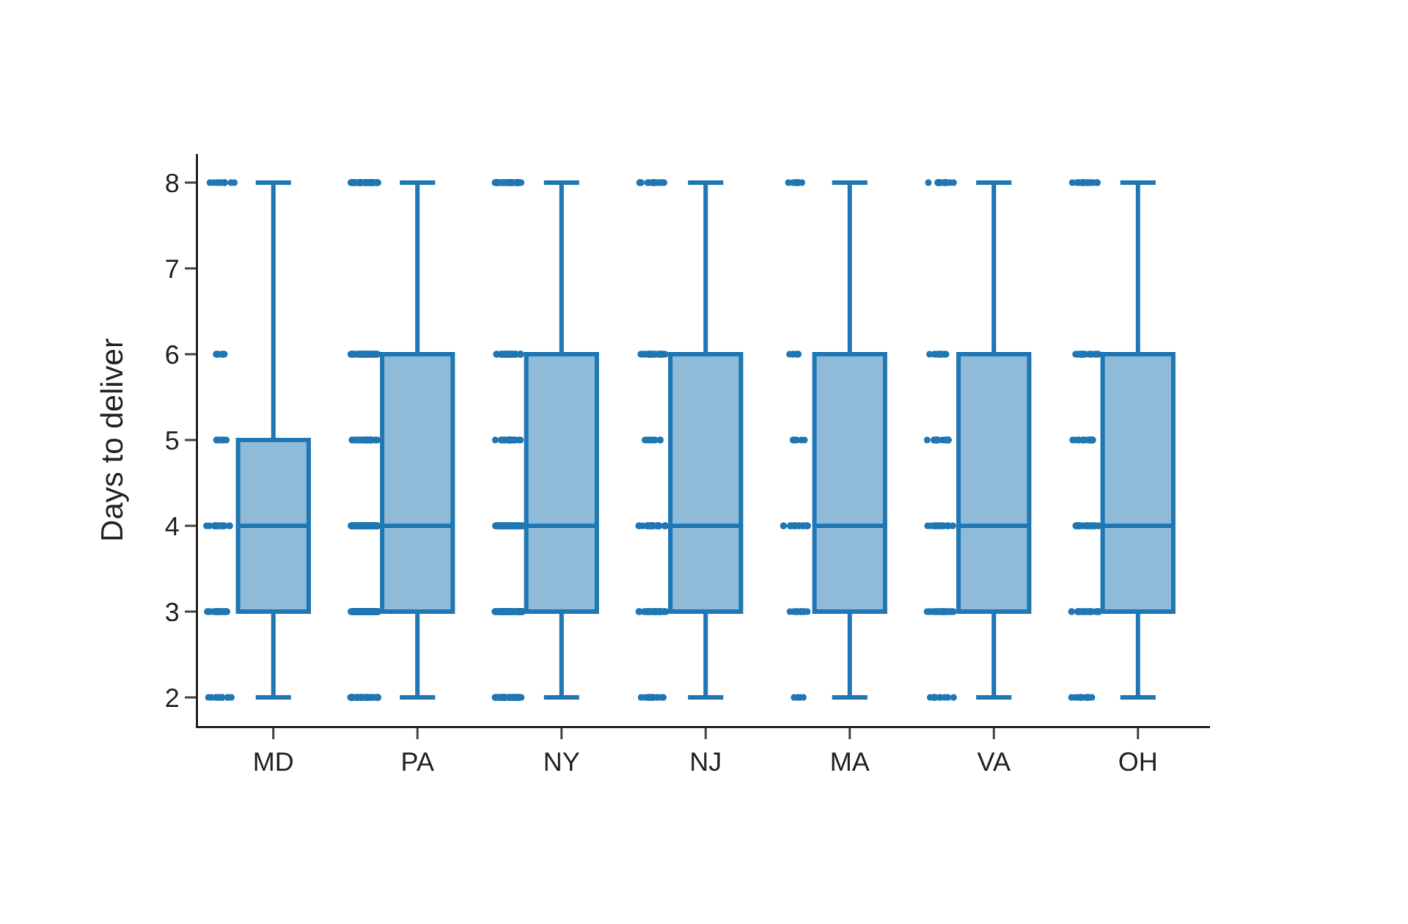

In [ ]:
data = orders.dropna(subset=["shipping_days", "state"]).astype(
    {"shipping_days": int})
order = (data.groupby("state")["shipping_days"].mean()
         .sort_values().index.tolist())
fig = px.box(data, x="state", y="shipping_days", points="all",
             category_orders={"state": order}, template="simple_white",
             labels={"shipping_days": "Days to deliver", "state": ""})
fig.update_traces(jitter=0.4, marker_size=3)
fig.show()
print(data.groupby("state")["shipping_days"].mean().round(2)
      .sort_values().to_dict())

*Delivery days by state as box plots, with every order shown as a jittered point.*

`points="all"` draws every order beside its box, and `jitter` spreads them sideways. Ordering the states by their mean delivery time puts the slowest on the right. The differences are small: every state has fast and slow deliveries, with means between about 4.2 and 4.6 days, confirming Chapter 14's finding that slow delivery isn't a regional problem.

## Exercise 17.4

*Make a choropleth of GDP per capita in 2007, with a logarithmic color scale.*

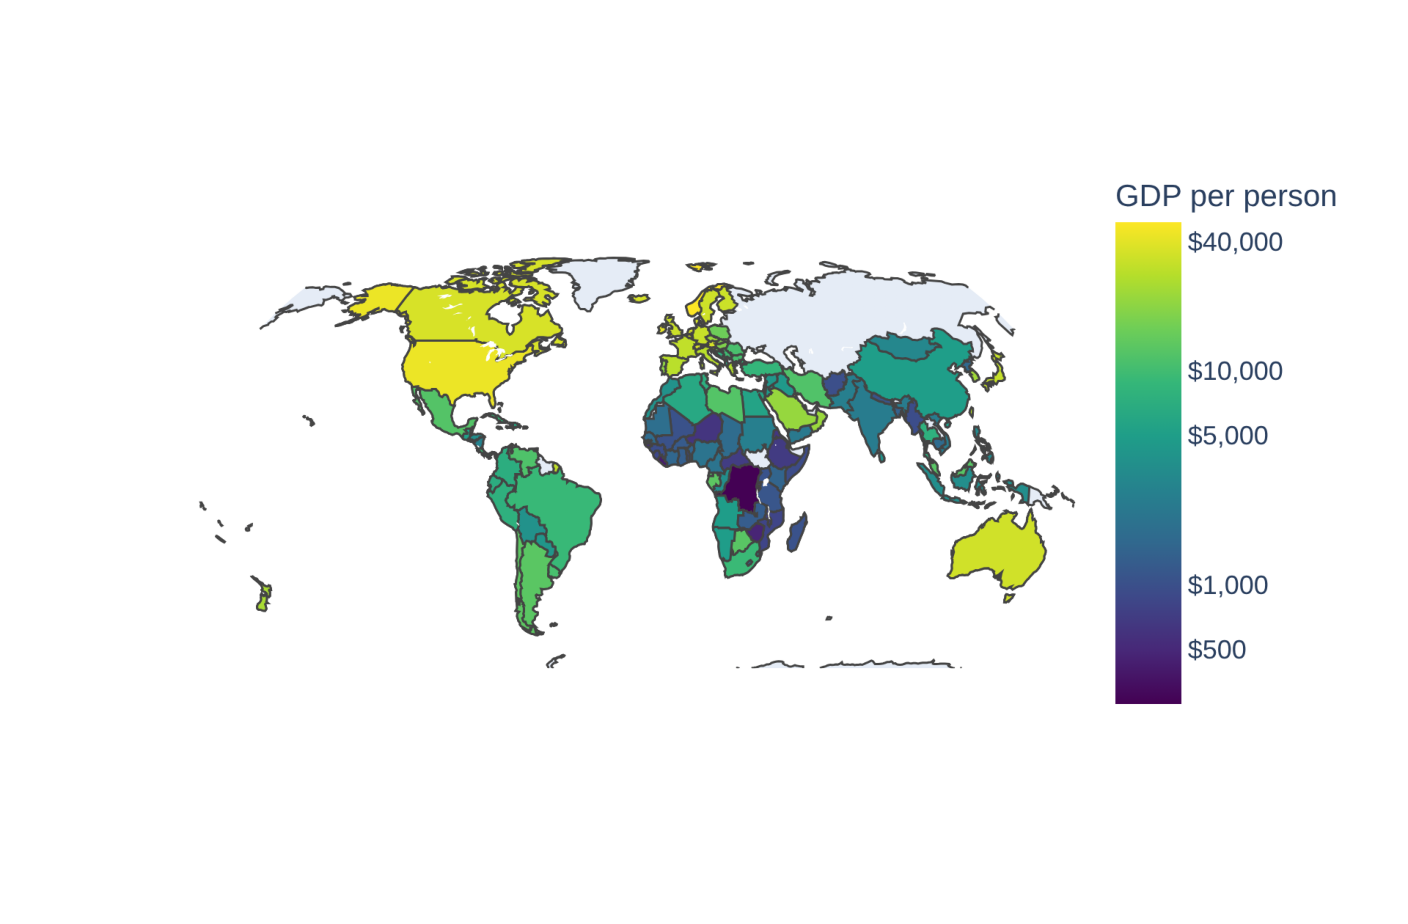

In [ ]:
data = y2007.assign(log_gdp=np.log10(y2007["gdpPercap"]))
ticks = [500, 1000, 5000, 10000, 40000]
fig = px.choropleth(data, locations="iso3", color="log_gdp",
                    hover_name="country",
                    hover_data={"gdpPercap": ":$,.0f", "log_gdp": False,
                                "iso3": False},
                    color_continuous_scale="Viridis")
fig.update_coloraxes(colorbar_title="GDP per person",
                     colorbar_tickvals=np.log10(ticks),
                     colorbar_ticktext=[f"${t:,}" for t in ticks])
fig.update_geos(showframe=False, projection_type="natural earth")
fig.show()

*GDP per person in 2007 on a logarithmic color scale.*

Plotly has no log option for color, so we color by the base-10 logarithm and label the color bar with the original values: `colorbar_tickvals` sets the positions, in logarithms, and `colorbar_ticktext` the labels. On a linear scale, almost every poor country would share one dark color; the log scale shows the differences among them too. The hover box hides the logarithm and shows the real value.

## Exercise 17.5

*Animate the coffee shop's cumulative revenue per product over the months with `px.bar` and `animation_frame`, with a fixed x range.*

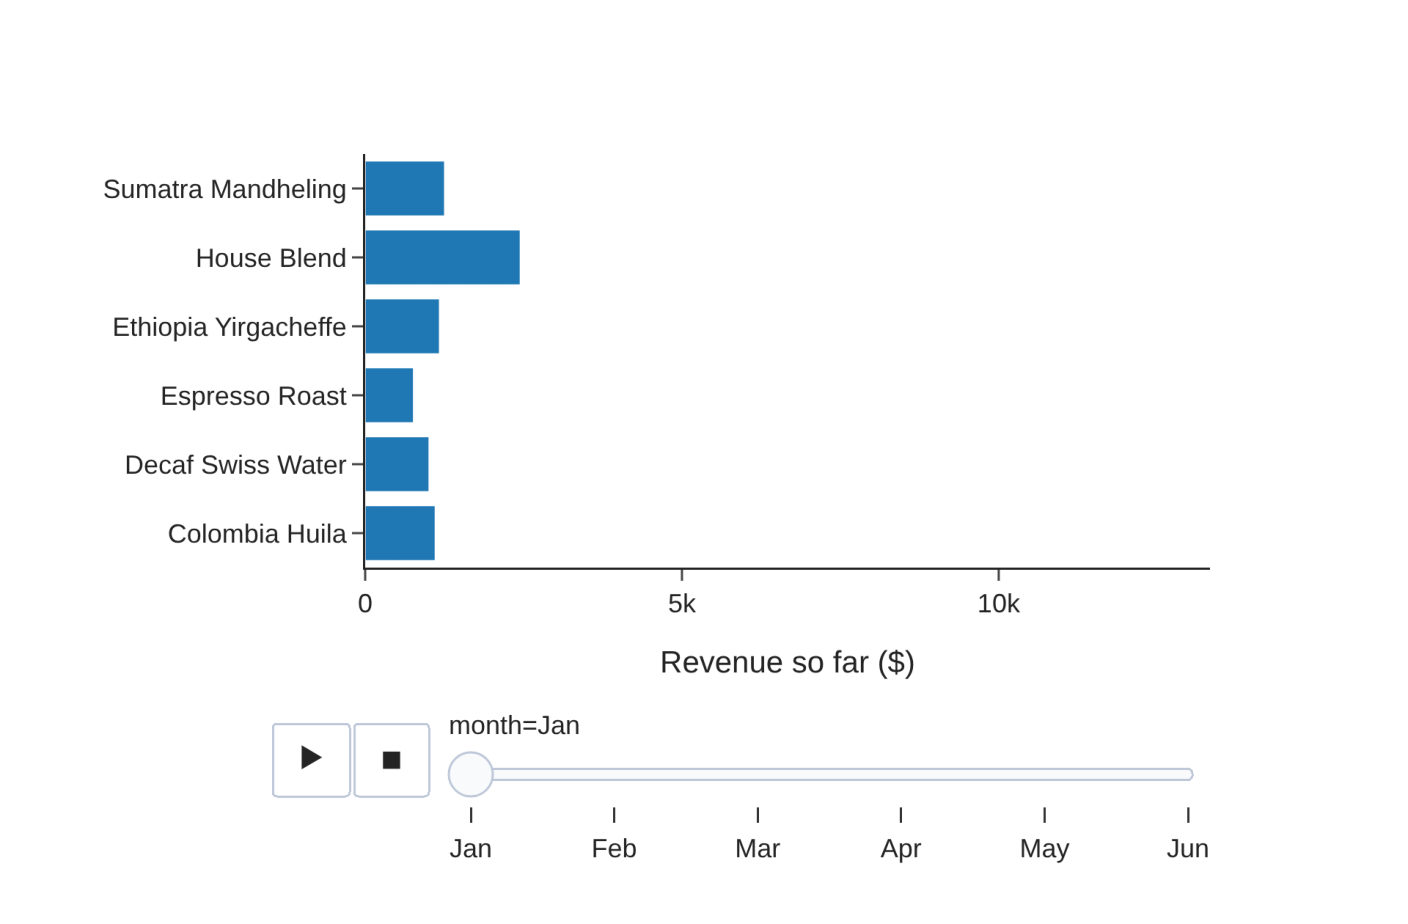

In [ ]:
monthly = (orders.groupby(["month", "product"])["revenue"].sum()
           .unstack(fill_value=0).cumsum().stack()
           .rename("revenue").reset_index())
monthly["month"] = monthly["month"].dt.strftime("%b")
fig = px.bar(monthly, x="revenue", y="product", orientation="h",
             animation_frame="month",
             range_x=[0, monthly["revenue"].max() * 1.05],
             template="simple_white",
             labels={"revenue": "Revenue so far ($)", "product": ""})
fig.show()

*Cumulative revenue per product, the first frame of the animation (January).*

`unstack(fill_value=0)` makes one column per product with a zero for any month without sales, so `cumsum` runs down each column; `stack` turns the table back into long form. The fixed `range_x` keeps the axis still while the bars grow. On screen, pressing play shows the House Blend's lead jump in February with the café's wholesale order.

## Exercise 17.6

*Save one of your charts as HTML with and without the CDN option, then save it as a PNG at twice the default resolution.*

In [ ]:
fig = px.scatter(y2007, x="gdpPercap", y="lifeExp", color="continent",
                 hover_name="country", log_x=True)
fig.write_html("chart.html")
fig.write_html("chart_cdn.html", include_plotlyjs="cdn")
fig.write_image("chart.png", scale=2)
for name in ["chart.html", "chart_cdn.html", "chart.png"]:
    print(f"{name:<15} {Path(name).stat().st_size:>10,} bytes")

chart.html       4,830,499 bytes
chart_cdn.html      14,835 bytes
chart.png          112,485 bytes


The self-contained HTML file is about 4.8 MB and opens anywhere; the CDN version is a few kilobytes and shows a blank page without a connection. `scale=2` doubles the PNG's resolution, which keeps it sharp in documents and on high-resolution screens.

## Exercise 17.7

*Extend the one-page report with a third chart, life expectancy by continent as lines, and a table of the five countries that gained the most years.*

In [ ]:
by_continent = (gap.groupby(["continent", "year"], as_index=False)
                ["lifeExp"].mean())
lines = px.line(by_continent, x="year", y="lifeExp", color="continent",
                markers=True, template="simple_white")
wide = gap.pivot(index="country", columns="year", values="lifeExp")
gains = (wide[2007] - wide[1952]).nlargest(5).round(1)
table = gains.rename("years gained").to_frame().to_html()
page = f"""<!DOCTYPE html><html><head><meta charset="utf-8">
<title>Life expectancy by continent</title></head>
<body style="font-family: sans-serif; max-width: 900px; margin: auto">
<h1>Life expectancy by continent, 1952-2007</h1>
{lines.to_html(full_html=False, include_plotlyjs="cdn")}
<h2>The five biggest gains</h2>{table}</body></html>"""
Path("continents.html").write_text(page, encoding="utf-8")
print(gains)

country
Oman            38.1
Vietnam         33.8
Indonesia       33.2
Saudi Arabia    32.9
Libya           31.2
dtype: float64


`DataFrame.to_html` writes a table as HTML, which sits in the page next to the chart. Oman, Vietnam, Indonesia, Saudi Arabia and Libya gained the most, each more than 30 years in half a century. The same pattern, charts and tables as HTML pieces in one f-string, adds as many sections as a report needs.